# 07b. A guard layer for the invariants

**Why.** Notebook 07 showed the chosen model fails two invariants: zero commits do not always give 0, and 200 one-line commits score 0.78.
The protocol rejects a model that breaks an invariant. The earlier Effort work reached the same conclusion and fixed it with deterministic
rules in front of a statistical model.

**The rules (all deterministic; the model itself is unchanged)**

1. **Zero rule.** No commits gives exactly 0.
2. **Lines per commit.** A commit is counted only when it carries at least `L` lines: commits become `min(commits, lines / L)`.
3. **Files per commit.** Files are counted up to `F` per commit: files become `min(files, F x commits)`.

**How `L` and `F` are chosen.** On **validation** data and made-up probes only; the test groups are not touched. A setting must pass all
three invariants; among those, the one with the lowest validation error is taken.

**Protocol status.** This is an amendment made after seeing notebook 07's results and before any test group is scored; it is logged in the
protocol's amendment table as a post-hoc change.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"
sys.path.insert(0, str(Path("training").resolve()))
warnings.filterwarnings("ignore")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from common import RESULTS, SEED, SPLITS, environment, group_bootstrap, load, log_run, metrics, paired_diff_bootstrap
from features import FEATURE_SETS, LABEL_SOURCES, add_team_context, feature_matrix, training_set
from final import fit_chosen, make_model, roles_for

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 190)
pd.set_option("display.max_columns", 40)
d = add_team_context(load().set_index("record_id", drop=False))
GOLD = d[d.label_source == "rater"]
choice = json.loads((RESULTS / "model_choice.json").read_text())
print(environment())
print("model chosen in notebook 05:", choice)

from final import apply_guard, predict_guarded
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FS, KIND = choice["feature_set"], ("linear" if choice["model"] == "Ridge" else "tree")
splits = pd.read_csv(SPLITS)
combos = [(t, v, g[["record_id", "role"]]) for (t, v), g in splits.groupby(["outer_test", "inner_val"])]
choices = json.loads((RESULTS / "tuning_choices.json").read_text())

{'python': '3.11.14', 'numpy': '2.4.6', 'pandas': '3.0.6', 'scipy': '1.17.1', 'sklearn': '1.9.1', 'seed': 20261018, 'data_hash': '2a23bdaa674b', 'splits_hash': 'b5793a57b501'}
model chosen in notebook 05: {'model': 'Ridge', 'feature_set': '3 features (chosen)', 'reason': 'no forest or boosting model passes protocol conditions 1-3 against Ridge', 'validation_MAE': 0.0774}


## 1. Validation error of every guard setting

In [2]:
GRID = [{"lines_per_commit": L, "files_per_commit": F, "zero_rule": True} for L in (0, 10, 25, 50, 100) for F in (0, 20, 40, 80)]
NO_GUARD = {"lines_per_commit": 0, "files_per_commit": 0, "zero_rule": False}


def val_mae(guard):
    errs = []
    for test, val, roles in combos:
        pick = choices[choice["model"]][FS][test]
        X, y, w, ids = training_set(d, roles, lambda f: feature_matrix(f, FS, KIND), pick["label_source"], pick["weight"], real_only=False)
        mdl = make_pipeline(StandardScaler(), Ridge(alpha=pick["params"]["alpha"])).fit(X, y, ridge__sample_weight=w)
        v = d.loc[[i for i in roles[roles.role == "val"].record_id if i in GOLD.index]]
        errs += list(np.abs(predict_guarded(mdl, v, FS, KIND, guard) - v.rater_effort.to_numpy()))
    return float(np.mean(errs))


val = pd.DataFrame([{**g, "validation MAE": val_mae(g)} for g in [NO_GUARD] + GRID])
val.round(4).head(12)

,lines_per_commit,files_per_commit,zero_rule,validation MAE
0,0,0,False,0.0703
1,0,0,True,0.0686
2,0,20,True,0.0685
3,0,40,True,0.0686
4,0,80,True,0.0686
5,10,0,True,0.0686
6,10,20,True,0.0685
7,10,40,True,0.0686
8,10,80,True,0.0686
9,25,0,True,0.0667


## 2. The invariants under each guard setting

In [3]:
FIT = {o: fit_chosen(d, o, choice["model"], FS, SEED)[0] for o in sorted(d.group.unique())}
BASE_ROW = {"E_CC": 8, "E_LOC_net_capped": 1500, "E_FC": 25, "E_CT": 2}
CASES = {"micro-commit spam": {"E_CC": 200, "E_LOC_net_capped": 200, "E_FC": 2, "E_CT": 0}, "library dump": {"E_CC": 1, "E_LOC_net_capped": 800, "E_FC": 1000, "E_CT": 0},
         "one huge commit": {"E_CC": 1, "E_LOC_net_capped": 800, "E_FC": 40, "E_CT": 1}, "many tiny real commits": {"E_CC": 40, "E_LOC_net_capped": 600, "E_FC": 12, "E_CT": 2},
         "typical active student": {"E_CC": 7, "E_LOC_net_capped": 1310, "E_FC": 21, "E_CT": 1}, "heavy contributor": {"E_CC": 40, "E_LOC_net_capped": 6000, "E_FC": 120, "E_CT": 5}}
GRIDS = {"E_CC": [0, 1, 2, 4, 8, 16, 32, 64, 128], "E_LOC_net_capped": [0, 100, 300, 800, 1500, 3000, 6000, 12000], "E_FC": [0, 2, 5, 10, 25, 50, 100, 200]}


def frame(rows):
    f = pd.DataFrame(rows)
    for c in ["E_CC", "E_LOC_net_capped", "E_FC", "E_CT", "E_RD"]:
        if c not in f:
            f[c] = 0
    f["rd_not_applicable"] = 0
    return f


def scores(rows, guard):
    f = frame(rows)
    return np.array([predict_guarded(m, f, FS, KIND, guard) for m in FIT.values()])


def invariants(guard):
    zero = scores([{"E_CC": 0, "E_LOC_net_capped": 0, "E_FC": 0, "E_CT": 0}], guard).max()
    mono = all(np.all(np.diff(scores([{**BASE_ROW, f: v} for v in vals], guard), axis=1) >= -1e-9) for f, vals in GRIDS.items())
    spam = scores([CASES["micro-commit spam"]], guard).max()
    dump = scores([CASES["library dump"]], guard).max()
    return {"zero": float(zero), "monotone": bool(mono), "spam max": float(spam), "dump max": float(dump),
            "pass": bool(zero <= 0.05 and mono and spam <= 0.35 and dump <= 0.35)}


inv = pd.DataFrame([{**g, **invariants(g)} for g in [NO_GUARD] + GRID])
full = val.merge(inv, on=["lines_per_commit", "files_per_commit", "zero_rule"])
full.round(3)

,lines_per_commit,files_per_commit,zero_rule,validation MAE,zero,monotone,spam max,dump max,pass
0,0,0,False,0.070,0.063,True,1.000,0.482,False
1,0,0,True,0.069,0.000,True,1.000,0.482,False
2,0,20,True,0.069,0.000,True,1.000,0.347,False
3,0,40,True,0.069,0.000,True,1.000,0.365,False
4,0,80,True,0.069,0.000,True,1.000,0.387,False
5,10,0,True,0.069,0.000,True,0.647,0.482,False
6,10,20,True,0.069,0.000,True,0.647,0.347,False
7,10,40,True,0.069,0.000,True,0.647,0.365,False
8,10,80,True,0.069,0.000,True,0.647,0.387,False
9,25,0,True,0.067,0.000,True,0.486,0.482,False


## 3. Choose the setting

In [4]:
passing = full[full["pass"]].sort_values(["validation MAE", "lines_per_commit", "files_per_commit"])
print(len(passing), "of", len(GRID), "settings pass all three invariants")
passing.round(4).head(8)

1 of 20 settings pass all three invariants


,lines_per_commit,files_per_commit,zero_rule,validation MAE,zero,monotone,spam max,dump max,pass
18,100,20,True,0.0644,0.0,True,0.3035,0.3466,True


In [5]:
if len(passing):
    pick = passing.iloc[0]
    status = "all invariants pass"
else:
    pick = full[full.zero_rule].sort_values(["spam max", "dump max"]).iloc[0]
    status = "NO SETTING PASSES: the strictest caps are used and the failure is reported"
guard = {"lines_per_commit": int(pick.lines_per_commit), "files_per_commit": int(pick.files_per_commit), "zero_rule": True}
guard["validation_MAE_unguarded"] = round(float(val[val.zero_rule == False].iloc[0]["validation MAE"]), 4)
guard["validation_MAE_guarded"] = round(float(pick["validation MAE"]), 4)
guard["invariants"] = {k: (float(pick[k]) if k != "monotone" else bool(pick[k])) for k in ("zero", "monotone", "spam max", "dump max")}
guard["status"] = status
(RESULTS / "guard_choice.json").write_text(json.dumps(guard, indent=2))
print(json.dumps(guard, indent=2))

{
  "lines_per_commit": 100,
  "files_per_commit": 20,
  "zero_rule": true,
  "validation_MAE_unguarded": 0.0703,
  "validation_MAE_guarded": 0.0644,
  "invariants": {
    "zero": 0.0,
    "monotone": true,
    "spam max": 0.30350466119694786,
    "dump max": 0.3466300327245468
  },
  "status": "all invariants pass"
}


## 4. Before and after

In [6]:
G = {k: v for k, v in guard.items() if k in ("lines_per_commit", "files_per_commit", "zero_rule")}
rows = []
for label, g in (("without guard", NO_GUARD), ("with guard", G)):
    for case, row in CASES.items():
        s = scores([row], g)
        rows.append({"case": case, "version": label, "mean": float(s.mean()), "max over folds": float(s.max())})
pd.DataFrame(rows).pivot(index="case", columns="version", values=["mean", "max over folds"]).round(3)

mean               max over folds              
version                with guard without guard     with guard without guard
case                                                                        
heavy contributor           0.762         0.762          0.854         0.854
library dump                0.302         0.393          0.347         0.482
many tiny real commits      0.440         0.660          0.466         0.801
micro-commit spam           0.277         0.783          0.304         1.000
one huge commit             0.302         0.318          0.347         0.365
typical active student      0.486         0.486          0.508         0.508

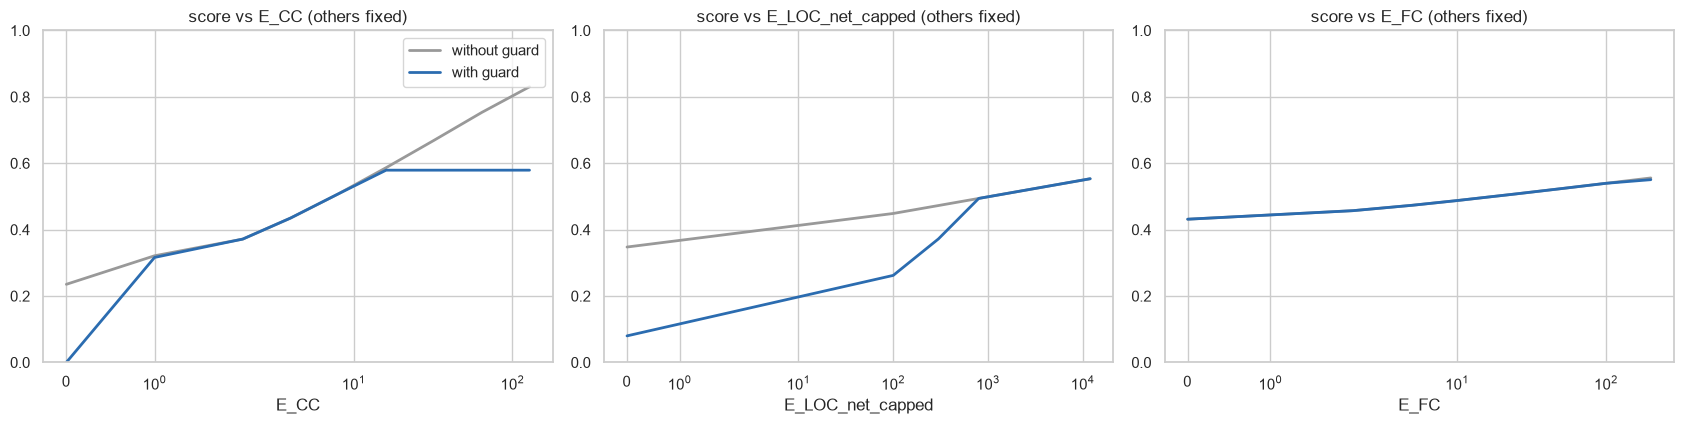

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for a, (feature, values) in zip(axes, GRIDS.items()):
    rows = [{**BASE_ROW, feature: v} for v in values]
    for g, color, label in ((NO_GUARD, "#999", "without guard"), (G, "#2b6cb0", "with guard")):
        a.plot(values, scores(rows, g).mean(axis=0), color=color, lw=2, label=label)
    a.set(title=f"score vs {feature} (others fixed)", xscale="symlog", ylim=(0, 1), xlabel=feature)
axes[0].legend()
plt.tight_layout()
plt.show()

## 5. Amendment record

In [8]:
amend = ("| 2026-10-18 | Added a deterministic guard layer (zero rule, lines per commit L=%d, files per commit F=%d) in front of the chosen model "
         "| The chosen model failed invariants 1 and 3 in notebook 07; the protocol rejects such a model "
         "| Yes: after notebook 07, before any test group was scored |") % (guard["lines_per_commit"], guard["files_per_commit"])
p = Path("PROTOCOL.md")
text = p.read_text(encoding="utf-8")
if "deterministic guard layer" not in text:
    p.write_text(text.rstrip("\n") + "\n" + amend + "\n", encoding="utf-8")
log_run("07b_guard_layer", f"{choice['model']} | {FS} + guard", json.dumps(G), {"MAE": guard["validation_MAE_guarded"], "MAE_unguarded": guard["validation_MAE_unguarded"]})
print(amend)

| 2026-10-18 | Added a deterministic guard layer (zero rule, lines per commit L=100, files per commit F=20) in front of the chosen model | The chosen model failed invariants 1 and 3 in notebook 07; the protocol rejects such a model | Yes: after notebook 07, before any test group was scored |


## 6. Reading the results

**Result: the guard layer fixes all three invariants and does not hurt accuracy.**

| | Without guard | With guard (L = 100 lines per commit, F = 20 files per commit, zero rule) |
|---|---|---|
| Zero commits | up to 0.063 | **0** in every fold |
| More never lowers the score | pass | pass |
| 200 one-line commits (spam) | 0.78 mean, 1.00 worst fold | **0.28**, 0.30 worst fold |
| Library dump (1,000 files) | 0.39 mean, 0.48 worst fold | **0.30**, 0.35 worst fold |
| Validation MAE | 0.0703 | **0.0644** |

**It improves the error as well.** Counting a commit only when it carries real lines removes credit that the labels did not give (the
weak students in the rated set are those with one or two small commits). The guarded model is more accurate on validation as well as safer.

**Read this result with care.**
- **Only 1 of the 20 settings passes**, at the strictest ends of both grids (L = 100, F = 20), and the library dump's worst fold (0.3466) is
  just under the 0.35 ceiling. The grid should be extended, and the setting is partly tuned to the probes it is tested on.
- **The cost to honest students.** "Many tiny real commits" (40 commits, 600 lines) drops from 0.66 to 0.44, because 600 lines support only
  six counted commits. That is a judgement about what a commit is worth, not something the labels tested; typical and heavy contributors are
  unchanged.
- The guard encodes rules about commit size that a lecturer should confirm. The amendment is logged in `PROTOCOL.md` as post-hoc.

Saved: `training/results/guard_choice.json`. Next: **08. Final test**, which now scores the guarded model.